# CSCN8000 – Lab 2: Probability & Statistics

This lab has two parts:

* **Part A – Spam classification:** use *Naive Bayes* (a probability-based model) to decide whether an email is **spam** or **ham** (not spam). I compare two versions: **Gaussian** and **Multinomial** Naive Bayes.
* **Part B – Outlier removal:** use measures of **central tendency** (mean, median) and **dispersion** (standard deviation, IQR, percentiles) to remove extreme prices from the New York City Airbnb dataset.

In [1]:
# Libraries used in this lab
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, ConfusionMatrixDisplay

pd.set_option("display.max_colwidth", 80)

---
# Part A – Spam vs. Ham with Naive Bayes

### What is Naive Bayes?
Naive Bayes uses **Bayes' theorem** to compute the probability that an email is spam given the words it contains:

$$P(\text{spam} \mid \text{words}) \propto P(\text{spam}) \times P(\text{word}_1 \mid \text{spam}) \times P(\text{word}_2 \mid \text{spam}) \times \dots$$

It is called *naive* because it assumes each word is independent of the others. That is not really true, but the model still works very well for text.

The model calculates this probability for both classes (spam and ham) and picks the larger one.

### Step 1 – Load and explore the data

In [2]:
spam_df = pd.read_csv("data/Lab2_dataset.csv")
print("Shape (rows, columns):", spam_df.shape)
spam_df.head()

Shape (rows, columns): (5171, 4)


,Unnamed: 0,label,text,label_num
0,605,ham,Subject: enron methanol ; meter # : 988291\nthis is a follow up to the note ...,0
1,2349,ham,"Subject: hpl nom for january 9 , 2001\n( see attached file : hplnol 09 . xls...",0
2,3624,ham,"Subject: neon retreat\nho ho ho , we ' re around to that most wonderful time...",0
3,4685,spam,"Subject: photoshop , windows , office . cheap . main trending\nabasements da...",1
4,2030,ham,Subject: re : indian springs\nthis deal is to book the teco pvr revenue . it...,0


The columns are:
* `Unnamed: 0` – an old index number, which we don't need
* `label` – the class as text (`ham` / `spam`)
* `text` – the email content
* `label_num` – the class as a number (`0` = ham, `1` = spam). This is our **target**.

In [3]:
# Drop the unused index column and check for missing values
spam_df = spam_df.drop(columns=["Unnamed: 0"])
print("Missing values per column:")
print(spam_df.isnull().sum())

# How many emails of each class?
counts = spam_df["label"].value_counts()
print("\nClass counts:")
print(counts)
print("\nClass percentages:")
print((counts / len(spam_df) * 100).round(1))

Missing values per column:
label        0
text         0
label_num    0
dtype: int64

Class counts:
label
ham     3672
spam    1499
Name: count, dtype: int64

Class percentages:
label
ham     71.0
spam    29.0
Name: count, dtype: float64


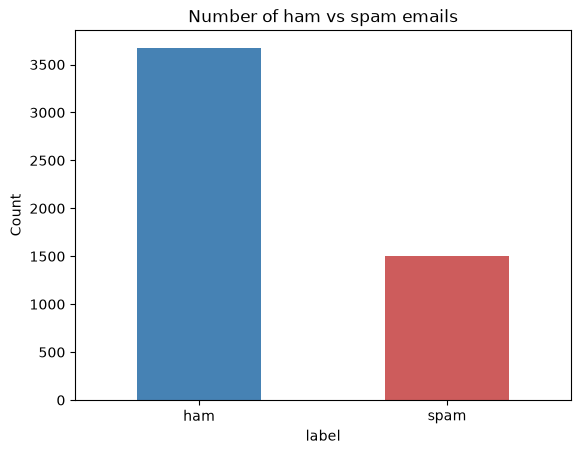

In [4]:
counts.plot(kind="bar", color=["steelblue", "indianred"])
plt.title("Number of ham vs spam emails")
plt.ylabel("Count")
plt.xticks(rotation=0)
plt.show()

**Insight:** about **71% ham and 29% spam**. The classes are imbalanced, so a model that always guessed "ham" would already be about 71% accurate. Any useful model has to do clearly better than 71%, and we should look at more than accuracy (for example, how many spam emails it actually catches).

### Step 2 – Split into train and test sets
* **Training set (80%)** – the model learns from these emails.
* **Test set (20%)** – the model has never seen these. I use them to check how well it works on new emails.

`stratify=y` keeps the same ham/spam ratio in both sets. `random_state=42` makes the split the same each time I run the notebook.

In [5]:
X = spam_df["text"]        # input: the email text
y = spam_df["label_num"]   # output: 0 = ham, 1 = spam

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training emails:", len(X_train))
print("Testing emails :", len(X_test))

Training emails: 4136
Testing emails : 1035


### Step 3 – Turn text into numbers (Bag of Words)
Models can only work with numbers, so I use `CountVectorizer` to turn each email into a row of **word counts**:

| | money | free | meeting | ... |
|---|---|---|---|---|
| email 1 | 2 | 3 | 0 | ... |
| email 2 | 0 | 0 | 1 | ... |

Settings used:
* `stop_words="english"` removes very common words like *the, and, is*, which don't help tell spam from ham.
* `max_features=3000` keeps only the 3,000 most frequent words. This keeps the data small enough for Gaussian NB, which needs a regular (dense) table.

**Important:** I `fit` the vectorizer on the **training data only** and then `transform` the test data with it. This way, no information from the test set leaks into training.

In [6]:
vectorizer = CountVectorizer(stop_words="english", max_features=3000)

X_train_counts = vectorizer.fit_transform(X_train)   # learn vocabulary + count words
X_test_counts  = vectorizer.transform(X_test)        # only count words (same vocabulary)

print("Training matrix shape:", X_train_counts.shape)
print("Example words in vocabulary:", vectorizer.get_feature_names_out()[1000:1010])

Training matrix shape: (4136, 3000)
Example words in vocabulary: ['ellis' 'elsa' 'em' 'email' 'emails' 'emerson' 'emirates' 'emotional'
 'employee' 'employees']


### Step 4 – Train the two Naive Bayes models

| Model | Assumes each feature follows... | Good for |
|---|---|---|
| **GaussianNB** | a bell curve (normal distribution) of continuous values | continuous measurements, e.g. height or temperature |
| **MultinomialNB** | counts of how often something appears | **word counts in text** |

Multinomial, in theory, is the "textbook" choice for word counts. I will test this assumption for my data. Both models get **exactly the same features**, so the comparison is fair.

In [7]:
# Gaussian Naive Bayes needs a regular (dense) array, not a sparse matrix
gnb = GaussianNB()
gnb.fit(X_train_counts.toarray(), y_train)
y_pred_gnb = gnb.predict(X_test_counts.toarray())

# Multinomial Naive Bayes works directly with the word counts
mnb = MultinomialNB()
mnb.fit(X_train_counts, y_train)
y_pred_mnb = mnb.predict(X_test_counts)

print("Gaussian NB accuracy   :", round(accuracy_score(y_test, y_pred_gnb), 4))
print("Multinomial NB accuracy:", round(accuracy_score(y_test, y_pred_mnb), 4))

Gaussian NB accuracy   : 0.9604
Multinomial NB accuracy: 0.944


### Step 5 – Evaluate in more detail
Accuracy alone can hide problems, so I will also look at:
* **Confusion matrix** – how many emails were classified correctly or incorrectly in each class.
* **Precision (spam)** – of the emails the model *called* spam, how many really were spam? (Low precision means real emails end up in the spam folder.)
* **Recall (spam)** – of all the *real* spam emails, how many did the model catch?
* **F1-score** – a balance of precision and recall.

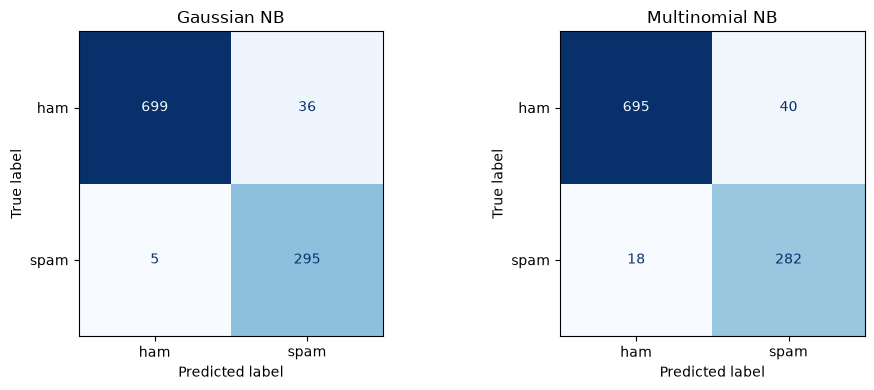

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, preds, title in zip(axes, [y_pred_gnb, y_pred_mnb], ["Gaussian NB", "Multinomial NB"]):
    ConfusionMatrixDisplay(confusion_matrix(y_test, preds), display_labels=["ham", "spam"]).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(title)
plt.tight_layout()
plt.show()

In [9]:
print("=== Gaussian NB ===")
print(classification_report(y_test, y_pred_gnb, target_names=["ham", "spam"]))
print("=== Multinomial NB ===")
print(classification_report(y_test, y_pred_mnb, target_names=["ham", "spam"]))

=== Gaussian NB ===
              precision    recall  f1-score   support

         ham       0.99      0.95      0.97       735
        spam       0.89      0.98      0.94       300

    accuracy                           0.96      1035
   macro avg       0.94      0.97      0.95      1035
weighted avg       0.96      0.96      0.96      1035

=== Multinomial NB ===
              precision    recall  f1-score   support

         ham       0.97      0.95      0.96       735
        spam       0.88      0.94      0.91       300

    accuracy                           0.94      1035
   macro avg       0.93      0.94      0.93      1035
weighted avg       0.95      0.94      0.94      1035



In [10]:
# Side-by-side summary table
from sklearn.metrics import precision_score, recall_score, f1_score

results = pd.DataFrame({
    "Model": ["Gaussian NB", "Multinomial NB"],
    "Accuracy":  [accuracy_score(y_test, p)  for p in (y_pred_gnb, y_pred_mnb)],
    "Precision (spam)": [precision_score(y_test, p) for p in (y_pred_gnb, y_pred_mnb)],
    "Recall (spam)":    [recall_score(y_test, p)    for p in (y_pred_gnb, y_pred_mnb)],
    "F1 (spam)":        [f1_score(y_test, p)        for p in (y_pred_gnb, y_pred_mnb)],
}).round(4)
results

,Model,Accuracy,Precision (spam),Recall (spam),F1 (spam)
0,Gaussian NB,0.9604,0.8912,0.9833,0.9350
1,Multinomial NB,0.9440,0.8758,0.9400,0.9068


### Which model performs better?
With the same 3,000 word-count features, **Gaussian NB performed better** on this test set. It has higher accuracy, precision, recall and F1 for spam.

This is a bit surprising, because Multinomial NB is usually recommended for text. One test split could be luck, so I will repeat the experiment with **5 different random splits**:

In [11]:
rows = []
for seed in range(5):
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, random_state=seed, stratify=y)
    vec = CountVectorizer(stop_words="english", max_features=3000)
    A, B = vec.fit_transform(Xtr), vec.transform(Xte)
    rows.append({
        "split (random_state)": seed,
        "Gaussian NB":    accuracy_score(yte, GaussianNB().fit(A.toarray(), ytr).predict(B.toarray())),
        "Multinomial NB": accuracy_score(yte, MultinomialNB().fit(A, ytr).predict(B)),
    })
repeat = pd.DataFrame(rows).set_index("split (random_state)").round(4)
repeat.loc["average"] = repeat.mean().round(4)
repeat

,Gaussian NB,Multinomial NB
split (random_state),,
0,0.9633,0.9565
1,0.9517,0.9498
2,0.9652,0.9536
3,0.9643,0.9440
4,0.9536,0.9469
average,0.9596,0.9502


**Gaussian NB wins on every split**, so the result is consistent and not just luck.

A possible reason: I kept only the 3,000 most common words. Gaussian NB learns an average count *and* a spread (variance) for every word in each class, which gives it extra detail to work with. Multinomial NB only learns how often each word appears in each class.

**One extra experiment.** Multinomial NB has a practical advantage: it works with *sparse* data (it only stores the non-zero counts), so it can use the **whole vocabulary** of about 45,000 words. Gaussian NB needs a full dense table, which would take about 1.5 GB of memory at that size, so I can't run it there. Let's see how Multinomial does with every word:

In [12]:
vec_full = CountVectorizer(stop_words="english")          # no word limit
A_full, B_full = vec_full.fit_transform(X_train), vec_full.transform(X_test)

mnb_full = MultinomialNB().fit(A_full, y_train)
print("Vocabulary size:", A_full.shape[1])
print("Multinomial NB accuracy with full vocabulary:", round(accuracy_score(y_test, mnb_full.predict(B_full)), 4))

Vocabulary size: 43482
Multinomial NB accuracy with full vocabulary: 0.9758


### Conclusion for the comparison
* **Fair test (same 3,000 features): Gaussian NB performs better** (about 96% vs 94–95% accuracy, and it catches more spam: recall 0.98 vs 0.94).
* If each model uses what it handles best, Multinomial NB with the full vocabulary reaches a similar or slightly higher accuracy, and it is much faster and lighter on memory.
* **Lesson:** the "textbook" choice is a good starting point, but we should always **test models on our own data**.

Since the **Gaussian NB** model performed better in the fair test, I will use the **Gaussian NB** model for the predictions below.

### Step 6 – Make predictions on test data
First, let's look at some test emails the model has never seen and compare its prediction with the true label.

In [13]:
label_name = {0: "ham", 1: "spam"}

sample = X_test.sample(10, random_state=1)
sample_vec = vectorizer.transform(sample).toarray()
sample_pred = gnb.predict(sample_vec)
sample_prob = gnb.predict_proba(sample_vec)[:, 1]   # probability of spam

preview = pd.DataFrame({
    "email (first 70 chars)": sample.str[:70].str.replace("\n", " "),
    "actual": y_test.loc[sample.index].map(label_name),
    "predicted": pd.Series(sample_pred, index=sample.index).map(label_name),
    "P(spam)": sample_prob.round(3),
})
preview

,email (first 70 chars),actual,predicted,P(spam)
1565,"Subject: calpine daily gas nomination julie , we should stay the same",ham,ham,0.0
4115,Subject: april availabilities - - - - - - - - - - - - - - - - - - - -,ham,ham,0.0
3901,Subject: ordering this pain medication page is loading . . image not s,spam,spam,1.0
3642,"Subject: revision # 1 - enron actuals for may 11 , 2000 correct number",ham,ham,0.0
1723,Subject: nomination change on tejas effective 7 / 8 / 00 devon changes,ham,ham,0.0
4164,"Subject: enron / hpl actuals for sept . 11 , 2000 teco tap 25 . 000 /",ham,ham,0.0
4855,Subject: popular meds at lowest prices we are now carrying v / alium !,spam,spam,1.0
1112,Subject: 5 th noms - - - - - - - - - - - - - - - - - - - - - - forward,ham,ham,0.0
959,Subject: reliant energy - entex transport imbalance - - - - - - - - -,ham,ham,0.0
3935,Subject: meoh plant status the methanol plant is still on target to be,ham,ham,0.0


I also try it on brand-new messages that I have written myself. The model is very confident about the spam messages, but it is less confident about the ham messages. This is because the training set has **more ham than spam**, so the model is biased toward ham.:

In [14]:
new_emails = [
    "Subject: Congratulations! You have won a FREE prize. Click here now to claim your cash reward",
    "Subject: meeting tomorrow - please send me the updated gas volume report before 10 am",
    "Subject: cheap viagra and discount software, limited time offer, buy now",
    "Subject: re: hpl nomination for march, see attached file",
]
new_vec = vectorizer.transform(new_emails).toarray()
new_pred = gnb.predict(new_vec)
new_prob = gnb.predict_proba(new_vec)[:, 1]

for text, pred, prob in zip(new_emails, new_pred, new_prob):
    print(f"[{label_name[pred].upper():4}]  P(spam)={prob:.3f}  ->  {text}")

[SPAM]  P(spam)=1.000  ->  Subject: Congratulations! You have won a FREE prize. Click here now to claim your cash reward
[SPAM]  P(spam)=1.000  ->  Subject: meeting tomorrow - please send me the updated gas volume report before 10 am
[SPAM]  P(spam)=1.000  ->  Subject: cheap viagra and discount software, limited time offer, buy now
[HAM ]  P(spam)=0.000  ->  Subject: re: hpl nomination for march, see attached file


**Insight:** Gaussian NB marked the normal "meeting tomorrow" email as **spam**. My handwritten emails are very short and use words (like *meeting*, *report*, *tomorrow*) that it sees only now and then in training. Gaussian NB treats every word count as a bell curve with a very small spread, so one unusual count can push it strongly to one class. This is also where its lower ham recall (0.95) shows up: it sends some real emails to spam.

Let's compare both models on the same handwritten emails:

In [15]:
pd.DataFrame({
    "email": [e[:60] for e in new_emails],
    "Gaussian NB": [label_name[p] for p in gnb.predict(new_vec)],
    "Multinomial NB": [label_name[p] for p in mnb.predict(vectorizer.transform(new_emails))],
})

,email,Gaussian NB,Multinomial NB
0,Subject: Congratulations! You have won a FREE prize. Click h,spam,spam
1,Subject: meeting tomorrow - please send me the updated gas v,spam,ham
2,"Subject: cheap viagra and discount software, limited time of",spam,spam
3,"Subject: re: hpl nomination for march, see attached file",ham,ham


The two models disagree on the "meeting" email. Multinomial NB gets it right, because it combines how often each word appears in spam vs ham and is less thrown off by one rare word. **No model is perfect:** Gaussian NB scored better on the test set overall, but checking individual predictions shows where it can fail.

**Part A takeaways**
* Naive Bayes is simple and fast, and it works very well for spam detection.
* With the same features, **Gaussian NB beat Multinomial NB** on this dataset, even though Multinomial is the usual textbook choice for text. Always test instead of assuming.
* Use **more than accuracy** (precision, recall, confusion matrix) to understand the kinds of mistakes a model makes.
* The model also gives a **probability** (`predict_proba`), which tells us how confident it is in each prediction. Naive Bayes probabilities are often very close to 0 or 1, so treat them as a rough confidence, not an exact value.

---
# Part B – Removing price outliers from NYC Airbnb data

An **outlier** is a value that is very far from most of the other values. Outliers can come from:
* data entry errors (e.g. a price of $0),
* real but unusual cases (e.g. a luxury penthouse at $10,000/night).

They can distort statistics like the mean and hurt machine-learning models. The goal is to remove extreme **price per night** values and produce a clean dataset.

### Step 1 – Load and explore

In [16]:
airbnb = pd.read_csv("data/AB_NYC_2019.csv")
print("Shape:", airbnb.shape)
airbnb[["name", "neighbourhood_group", "room_type", "price", "minimum_nights"]].head()

Shape: (48895, 16)


,name,neighbourhood_group,room_type,price,minimum_nights
0,Clean & quiet apt home by the park,Brooklyn,Private room,149,1
1,Skylit Midtown Castle,Manhattan,Entire home/apt,225,1
2,THE VILLAGE OF HARLEM....NEW YORK !,Manhattan,Private room,150,3
3,Cozy Entire Floor of Brownstone,Brooklyn,Entire home/apt,89,1
4,Entire Apt: Spacious Studio/Loft by central park,Manhattan,Entire home/apt,80,10


In [17]:
airbnb["price"].describe().round(2)

count    48895.00
mean       152.72
std        240.15
min          0.00
25%         69.00
50%        106.00
75%        175.00
max      10000.00
Name: price, dtype: float64

**Insight:**
* The **mean ($152.72)** is much higher than the **median ($106)**. This is a sign that the data is **right-skewed**: a few very expensive listings pull the mean up.
* The **standard deviation ($240)** is bigger than the mean, so prices are very spread out.
* The **minimum is $0**, which is not a real price per night and must be a data error.
* The **maximum is $10,000**. 75% of listings cost $175 or less, so $10,000 is extreme.

Let's look at the shape of the data.

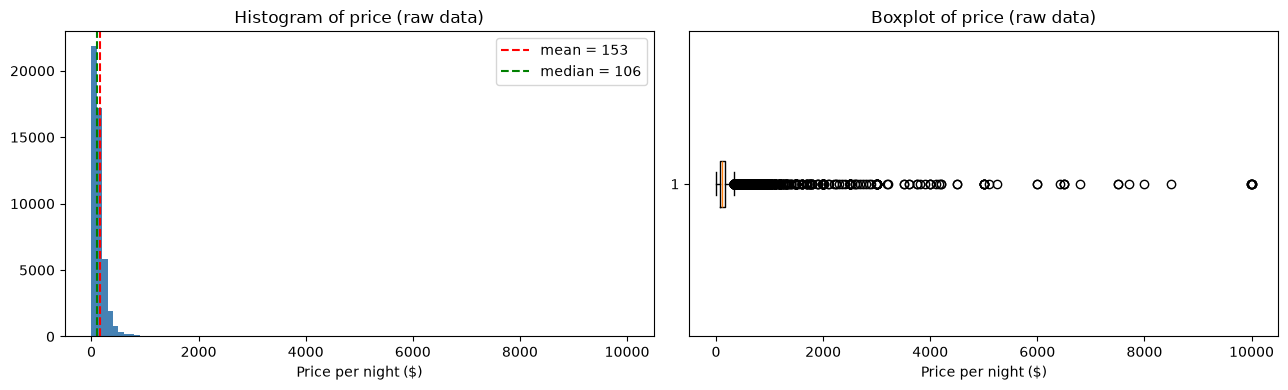

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].hist(airbnb["price"], bins=100, color="steelblue")
axes[0].axvline(airbnb["price"].mean(), color="red", linestyle="--", label=f"mean = {airbnb['price'].mean():.0f}")
axes[0].axvline(airbnb["price"].median(), color="green", linestyle="--", label=f"median = {airbnb['price'].median():.0f}")
axes[0].set_title("Histogram of price (raw data)")
axes[0].set_xlabel("Price per night ($)")
axes[0].legend()

axes[1].boxplot(airbnb["price"], orientation="horizontal")
axes[1].set_title("Boxplot of price (raw data)")
axes[1].set_xlabel("Price per night ($)")

plt.tight_layout()
plt.show()

The histogram has a long tail to the right, and the boxplot shows many points beyond the "whiskers". Those points are possible outliers.

### Step 2 – Mean vs. median: why the median is "robust"
A quick experiment: what happens to the mean and the median if we remove only the **10 most expensive** listings (0.02% of the data)?

In [19]:
without_top10 = airbnb["price"].sort_values().iloc[:-10]

print(f"Mean   with all data: {airbnb['price'].mean():.2f}   without top 10: {without_top10.mean():.2f}")
print(f"Median with all data: {airbnb['price'].median():.2f}   without top 10: {without_top10.median():.2f}")

Mean   with all data: 152.72   without top 10: 150.88
Median with all data: 106.00   without top 10: 106.00


**Insight:** removing just 10 rows moves the **mean** from $152.72 to $150.88, but the **median** stays the same.
* The **mean** is *sensitive* to outliers because every value is added into it.
* The **median** is *robust* because it only depends on the middle value.

This is why the most reliable outlier methods are based on the **median, quartiles, or percentiles**, not on the mean.

### Step 3 – Remove invalid prices ($0)
A price of $0 per night is not possible, so these rows are data errors and we remove them first.

In [20]:
print("Listings with price = 0:", (airbnb["price"] == 0).sum())
df = airbnb[airbnb["price"] > 0].copy()
print("Rows remaining:", len(df))

Listings with price = 0: 11
Rows remaining: 48884


Now we try several outlier-detection methods and compare them.

### Method 1 – Z-score (based on mean and standard deviation)
The z-score tells us how many standard deviations a value is from the mean:

$$z = \frac{x - \text{mean}}{\text{std}}$$

A common rule: if $|z| > 3$, the value is an outlier. This is the same as keeping values inside **mean ± 3 × std**.

In [21]:
mean_price = df["price"].mean()
std_price  = df["price"].std()

z_lower = mean_price - 3 * std_price
z_upper = mean_price + 3 * std_price
print(f"Mean = {mean_price:.2f}, Std = {std_price:.2f}")
print(f"Keep prices between {z_lower:.2f} and {z_upper:.2f}")

df_z = df[(df["price"] >= z_lower) & (df["price"] <= z_upper)]
print("Rows removed:", len(df) - len(df_z))

Mean = 152.76, Std = 240.17
Keep prices between -567.76 and 873.27
Rows removed: 388


**Insight:** the lower limit is **negative**, so the z-score method can never flag a cheap listing. The upper limit (about $873) is also very high.

This happens because the mean and standard deviation are themselves **inflated by the outliers** we want to remove. The z-score method works best when the data is roughly a **bell curve (normal)**, and the price data is strongly skewed, so this method is **not a good fit** here.

### Method 2 – IQR method (based on quartiles / median)
This is the rule used to draw the boxplot whiskers:
* **Q1** = 25th percentile, **Q3** = 75th percentile
* **IQR** = Q3 − Q1 (the range of the middle 50% of the data)
* Outlier if the value is **below Q1 − 1.5 × IQR** or **above Q3 + 1.5 × IQR**

Quartiles don't change much when there are extreme values, so this method is **robust**.

In [22]:
Q1 = df["price"].quantile(0.25)
Q3 = df["price"].quantile(0.75)
IQR = Q3 - Q1

iqr_lower = Q1 - 1.5 * IQR
iqr_upper = Q3 + 1.5 * IQR
print(f"Q1 = {Q1}, Q3 = {Q3}, IQR = {IQR}")
print(f"Keep prices between {iqr_lower} and {iqr_upper}")

df_iqr = df[(df["price"] >= iqr_lower) & (df["price"] <= iqr_upper)]
print("Rows removed:", len(df) - len(df_iqr))

Q1 = 69.0, Q3 = 175.0, IQR = 106.0
Keep prices between -90.0 and 334.0
Rows removed: 2972


**Insight:** the upper limit is **$334**, which is much tighter than the z-score's ~$873. The lower limit is negative again because prices are bunched near the low end, but I already removed the $0 prices.

### Method 3 – Percentile trimming
A simple, easy-to-explain method: keep only the values between two percentiles, e.g. the **1st and 99th**. This removes the cheapest 1% and the most expensive 1%.

In [23]:
p_lower = df["price"].quantile(0.01)
p_upper = df["price"].quantile(0.99)
print(f"1st percentile = {p_lower}, 99th percentile = {p_upper}")

df_pct = df[(df["price"] >= p_lower) & (df["price"] <= p_upper)]
print("Rows removed:", len(df) - len(df_pct))

1st percentile = 30.0, 99th percentile = 799.0
Rows removed: 867


**Insight:** percentile trimming is the only method so far that also removes **suspiciously cheap** listings (e.g. $10/night). The downside is that it *always* removes about 2% of the data, even if the data had no real outliers. The cutoff should be chosen based on the specific needs of the analysis (1/99, 5/95, ...).

### Method 4 – IQR by room type (our recommended method)
Looking at the price per night **for a given apartment/home**, different room types have very different normal prices:

In [24]:
df.groupby("room_type")["price"].describe().round(1)

,count,mean,std,min,25%,50%,75%,max
room_type,,,,,,,,
Entire home/apt,25407.0,211.8,284.0,10.0,120.0,160.0,229.0,10000.0
Private room,22319.0,89.8,160.2,10.0,50.0,70.0,95.0,10000.0
Shared room,1158.0,70.2,101.8,10.0,33.0,45.0,75.0,1800.0


A **$300 shared room** is very unusual, while a **$300 entire apartment** is quite normal. If only one limit is used for all listings, we:
* remove too many normal *entire homes*, and
* keep overpriced *shared/private rooms*.

Therefore, I apply the **IQR rule separately inside each room type**.

In [25]:
def iqr_bounds(prices):
    q1, q3 = prices.quantile(0.25), prices.quantile(0.75)
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

# Calculate the limits for every room type
bounds = df.groupby("room_type")["price"].apply(lambda p: pd.Series(iqr_bounds(p), index=["lower", "upper"])).unstack()
print(bounds)

# Attach each listing's limits and keep only listings inside them
df_group = df.join(bounds, on="room_type")
df_group = df_group[(df_group["price"] >= df_group["lower"]) & (df_group["price"] <= df_group["upper"])]
df_group = df_group.drop(columns=["lower", "upper"])
print("\nRows removed:", len(df) - len(df_group))

                 lower  upper
room_type                    
Entire home/apt  -43.5  392.5
Private room     -17.5  162.5
Shared room      -30.0  138.0

Rows removed: 3244


**Insight:** each room type now has its own fair upper limit: **$392.50** for entire homes, **$162.50** for private rooms and **$138** for shared rooms. The single IQR rule used $334 for everything, which removed normal entire homes priced between $335 and $392 and kept private rooms priced up to $334.

### Step 4 – Compare all methods

In [26]:
datasets = {
    "Original (no $0)":   df,
    "Z-score (±3 std)":   df_z,
    "IQR (all listings)": df_iqr,
    "Percentile 1–99%":   df_pct,
    "IQR by room type":   df_group,
}

comparison = pd.DataFrame({
    name: {
        "rows": len(d),
        "% removed": round((1 - len(d) / len(df)) * 100, 2),
        "mean": d["price"].mean(),
        "median": d["price"].median(),
        "std": d["price"].std(),
        "min": d["price"].min(),
        "max": d["price"].max(),
    }
    for name, d in datasets.items()
}).T.round(2)
comparison

,rows,% removed,mean,median,std,min,max
Original (no $0),48884.0,0.00,152.76,106.0,240.17,10.0,10000.0
Z-score (±3 std),48496.0,0.79,138.78,105.0,107.55,10.0,860.0
IQR (all listings),45912.0,6.08,120.00,100.0,68.13,10.0,334.0
Percentile 1–99%,48017.0,1.77,138.50,105.0,103.69,30.0,799.0
IQR by room type,45640.0,6.64,121.81,100.0,73.23,10.0,392.0


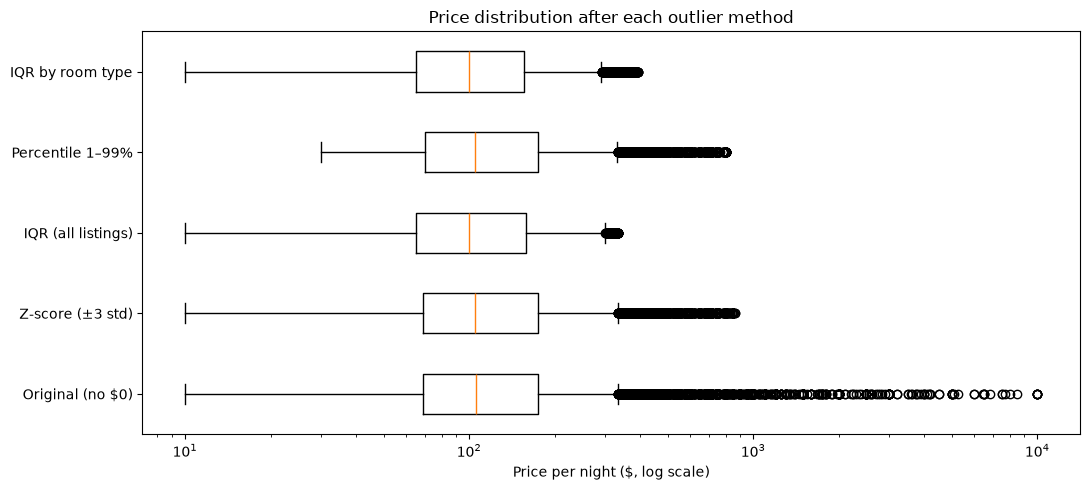

In [27]:
fig, ax = plt.subplots(figsize=(11, 5))
ax.boxplot([d["price"] for d in datasets.values()], tick_labels=list(datasets.keys()), orientation="horizontal")
ax.set_xscale("log")   # log scale so the huge original range still fits on one chart
ax.set_xlabel("Price per night ($, log scale)")
ax.set_title("Price distribution after each outlier method")
plt.tight_layout()
plt.show()

**What the comparison shows:**
* After cleaning, the **mean and median get much closer together**. This is a sign that the extreme values were pulling the mean away.
* The **standard deviation drops a lot** (from about $240 to under $100 for the IQR methods), so the data is far less spread out.
* **Z-score** removes the fewest rows and still keeps prices up to $860. It is too weak for skewed data.
* **IQR (all listings)** and **IQR by room type** remove a similar number of rows, but the group version uses limits that make sense for each type of home.
* **Percentile trimming** is the only method here that also removes the very cheap listings.

### Step 5 – Final clean dataset
**IQR was chosen by room type** as the final method because:
1. It is based on quartiles, so it is **robust** to the outliers themselves (unlike mean/std).
2. It judges each listing against **similar homes**, as the task asks ("price per night for a given apartment/home").
3. It keeps about **93%** of the data.

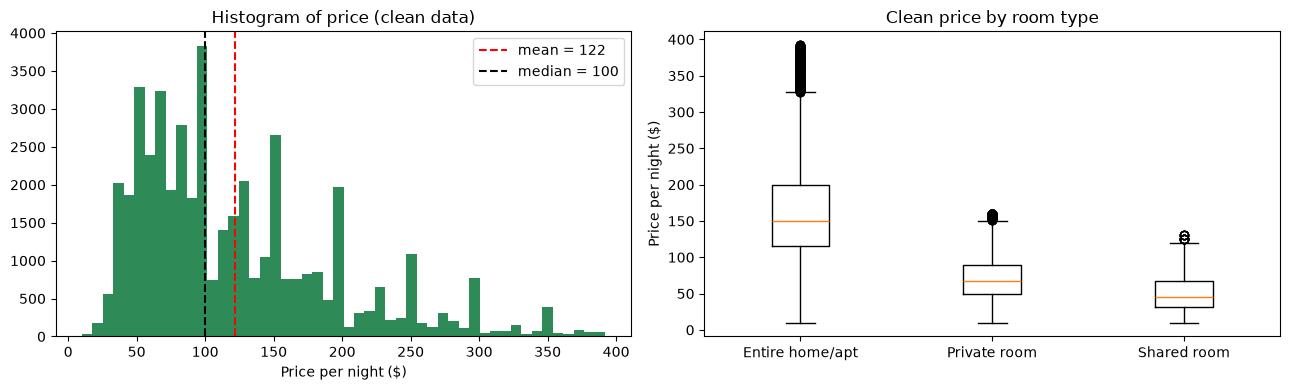

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].hist(df_group["price"], bins=50, color="seagreen")
axes[0].axvline(df_group["price"].mean(), color="red", linestyle="--", label=f"mean = {df_group['price'].mean():.0f}")
axes[0].axvline(df_group["price"].median(), color="black", linestyle="--", label=f"median = {df_group['price'].median():.0f}")
axes[0].set_title("Histogram of price (clean data)")
axes[0].set_xlabel("Price per night ($)")
axes[0].legend()

room_types = sorted(df_group["room_type"].unique())
axes[1].boxplot([df_group.loc[df_group["room_type"] == r, "price"] for r in room_types], tick_labels=room_types)
axes[1].set_title("Clean price by room type")
axes[1].set_ylabel("Price per night ($)")

plt.tight_layout()
plt.show()

In [29]:
df_group.to_csv("data/AB_NYC_2019_clean.csv", index=False)
print("Clean dataset saved:", df_group.shape)
print("Original rows:", len(airbnb), "-> clean rows:", len(df_group),
      f"({len(airbnb) - len(df_group)} removed, {100 * (len(airbnb) - len(df_group)) / len(airbnb):.1f}%)")

Clean dataset saved: (45640, 16)
Original rows: 48895 -> clean rows: 45640 (3255 removed, 6.7%)


**Part B takeaways**
* The **mean is sensitive** to outliers, and the **median is robust**. When data is skewed, use median/quartile-based methods.
* **Z-score** works best on bell-shaped (normal) data. On skewed prices it misses many outliers.
* **IQR** is the standard, robust rule (the same one used to draw boxplots).
* **Percentiles** are simple and also remove extreme low values, but the cut-off has to be chosen carefully.
* **Context matters:** comparing each listing only with similar homes (grouping by room type) gives fairer limits.

---
## Conclusion
* **Part A:** with the same 3,000 word-count features, Gaussian Naive Bayes classified spam better than Multinomial Naive Bayes (about 96% vs 94% accuracy), and this held across 5 random splits. Multinomial NB can use the full vocabulary cheaply, which brings it up to a similar level.
* **Part B:** after removing invalid $0 prices and applying the IQR rule per room type, we have a clean Airbnb dataset (`data/AB_NYC_2019_clean.csv`) with far less spread and a mean much closer to the median.